# 14-day cumulative number of COVID-19 cases per 100 000

At the end of the page, we provide a detailed description of how the numbers are calculated.

### Compute data

In [1]:
import datetime as dt
import pandas as pd
pd.set_option("max_rows", None)
from oscovida import get_incidence_rates_countries

## Table for all countries

In [2]:
cases_incidence, deaths_incidence = get_incidence_rates_countries()

Downloaded data: last data point 9/23/20 from https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv
Downloaded data: last data point 9/23/20 from https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_deaths_global.csv


In [3]:
cases_incidence

,14-day-sum,population,14-day-incidence-rate
Country,,,
Afghanistan,573,38928341,1.5
Albania,1927,2877800,67.0
Algeria,2912,43851043,6.6
Andorra,452,77265,585.0
Angola,1146,32866268,3.5
Antigua and Barbuda,2,97928,2.0
Argentina,140601,45195777,311.1
Armenia,2551,2963234,86.1
Australia,416,25459700,1.6


## Table sorted by 14-day-incidence

In [4]:
cases_incidence.sort_values(by=['14-day-incidence-rate'], ascending=False)

,14-day-sum,population,14-day-incidence-rate
Country,,,
Israel,59164,8655541,683.5
Andorra,452,77265,585.0
Bahrain,8807,1701583,517.6
Montenegro,3206,628062,510.5
Argentina,140601,45195777,311.1
Costa Rica,15510,5094114,304.5
Spain,139413,46754783,298.2
Bahamas,897,393248,228.1
Peru,73770,32971846,223.7


## Tutorial: Detailed calculation for one country

In [5]:
from oscovida import fetch_cases, get_population
import datetime

In [6]:
period = 14 # Days we compute the incidence rate over

In [7]:
cases = fetch_cases() # Get a DataFrame where each row is the country, and columns cumulative case numbers
cases = cases.groupby(cases.index).sum() # Merge the rows for different regions as we want the numbers for an entire country

In [8]:
cases_germany = cases.loc['Germany'][2:] # First 2 entries are lat/lon so we only take the subsequent ones
cases_germany.tail()

9/19/20    272932.0
9/20/20    273965.0
9/21/20    275560.0
9/22/20    277412.0
9/23/20    279025.0
Name: Germany, dtype: float64

In [9]:
yesterday = datetime.datetime.now() - datetime.timedelta(days=1)
x_days_ago = yesterday - datetime.timedelta(days=period)

In [10]:
period_mask = (
    (yesterday > pd.to_datetime(cases_germany.index)) &
    (pd.to_datetime(cases_germany.index) > x_days_ago)
) # Mask for dates between today and x days ago

In [11]:
cases_in_period_per_day_germany = cases_germany[period_mask].diff() # Apply the period mask and get the diff to get the daily new cases
cases_in_period_per_day_germany

9/10/20       NaN
9/11/20    1586.0
9/12/20    1082.0
9/13/20     920.0
9/14/20    1485.0
9/15/20    1792.0
9/16/20    1855.0
9/17/20    2179.0
9/18/20    2199.0
9/19/20    1685.0
9/20/20    1033.0
9/21/20    1595.0
9/22/20    1852.0
9/23/20    1613.0
Name: Germany, dtype: float64

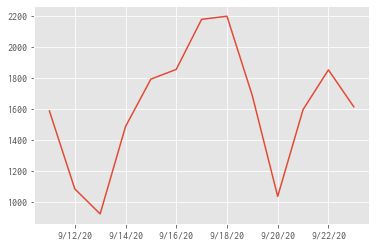

In [12]:
cases_in_period_per_day_germany.plot() # We can easily look at new cases per day

In [13]:
population = get_population().population

In [14]:
population_germany = population.loc['Germany'] # Get the population of Germany
population_germany

83783945.0

In [15]:
incidence_rate_germany = cases_in_period_per_day_germany.sum() / population_germany * 100_000
incidence_rate_germany # By convention this is total cases over period / population * 100_000

24.916468184924927